In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# ── Image Directory ──
IMAGE_DIR = '/Users/shubhbhateja/College/minor_project/images'


In [3]:


# ── Load all images ──
image_files = sorted([f for f in os.listdir(IMAGE_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
print(f"Found {len(image_files)} images in {IMAGE_DIR}")


Found 2235 images in /Users/shubhbhateja/College/minor_project/images


In [4]:

# Load images into a dictionary with filename as key
images = {}
for fname in image_files:
    img_path = os.path.join(IMAGE_DIR, fname)
    img = cv2.imread(img_path)
    if img is not None:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        images[fname] = img_rgb
    else:
        print(f"Failed to load: {fname}")

print(f"\nSuccessfully loaded {len(images)} images")


Successfully loaded 2235 images


In [5]:


# Display basic info
if images:
    first_img = list(images.values())[0]
    print(f"Image shape: {first_img.shape}")
    print(f"Image dtype: {first_img.dtype}")
    print(f"\nFirst 5 images: {list(images.keys())[:5]}")


Image shape: (567, 567, 3)
Image dtype: uint8

First 5 images: ['0001-1.jpg', '0001-2.jpg', '0001-3.jpg', '0002-1.jpg', '0002-2.jpg']


In [7]:
images

{'0001-1.jpg': array([[[147, 102,  71],
         [148, 101,  73],
         [147, 104,  70],
         ...,
         [ 80,  61,  44],
         [ 81,  64,  48],
         [ 84,  67,  51]],
 
        [[147, 102,  71],
         [147, 100,  72],
         [147, 104,  70],
         ...,
         [ 83,  64,  47],
         [ 86,  69,  53],
         [ 88,  71,  55]],
 
        [[146, 101,  70],
         [147, 102,  73],
         [147, 102,  69],
         ...,
         [ 85,  68,  52],
         [ 94,  75,  60],
         [ 95,  78,  62]],
 
        ...,
 
        [[237, 236, 231],
         [238, 235, 230],
         [236, 237, 231],
         ...,
         [201, 151, 100],
         [204, 154, 103],
         [202, 152, 101]],
 
        [[237, 236, 231],
         [239, 236, 231],
         [235, 236, 230],
         ...,
         [202, 152, 101],
         [202, 152, 101],
         [202, 152, 101]],
 
        [[237, 236, 231],
         [239, 236, 231],
         [236, 237, 231],
         ...,
         [201,

In [8]:
# ── Visualize sample images ──
num_samples = 6
sample_files = list(images.keys())[:num_samples]


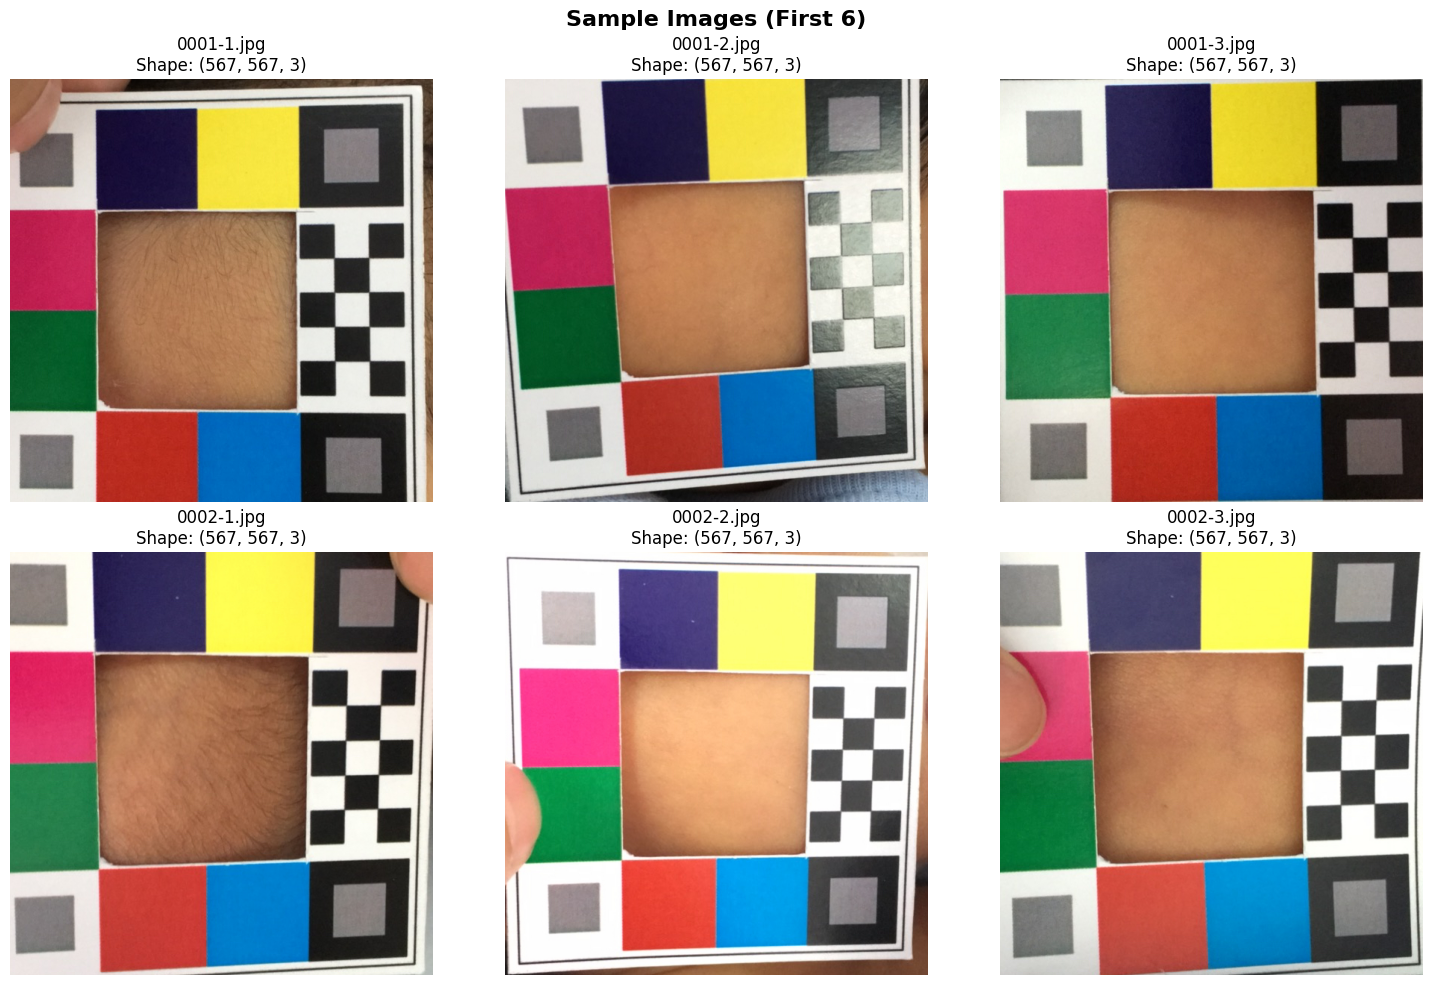


Displayed 6 sample images


In [17]:


fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()
for idx, fname in enumerate(sample_files):
    img = images[fname]
    axes[idx].imshow(img)
    axes[idx].set_title(f'{fname}\nShape: {img.shape}')
    axes[idx].axis('off')

plt.suptitle(f'Sample Images (First {num_samples})', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nDisplayed {len(sample_files)} sample images")


Loaded image: 0001-1.jpg
Image shape: (567, 567, 3)
Image dtype: uint8
Pixel value range: Min=0, Max=255



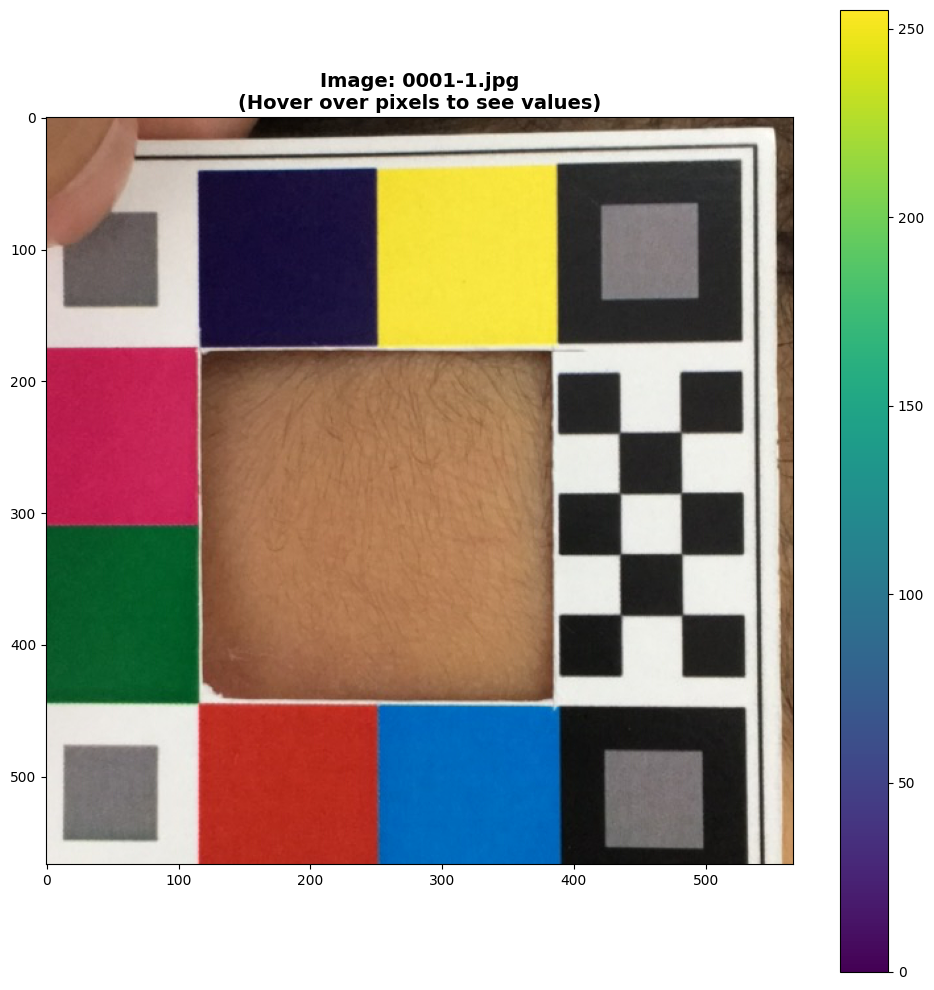


MANUAL PIXEL INSPECTION
Pixel at [0, 0]: RGB(147, 102, 71)
Pixel at [100, 100]: RGB(226, 219, 211)
Pixel at [283, 283]: RGB(179, 126, 86)

PIXEL STATISTICS

Red Channel:
  Min: 0, Max: 255, Mean: 136.54, Std: 83.15

Green Channel:
  Min: 4, Max: 255, Mean: 116.08, Std: 73.61

Blue Channel:
  Min: 0, Max: 250, Mean: 102.14, Std: 68.73
Original image shape: (567, 567, 3)
✅ Cropped to skin region: (391, 284, 3)


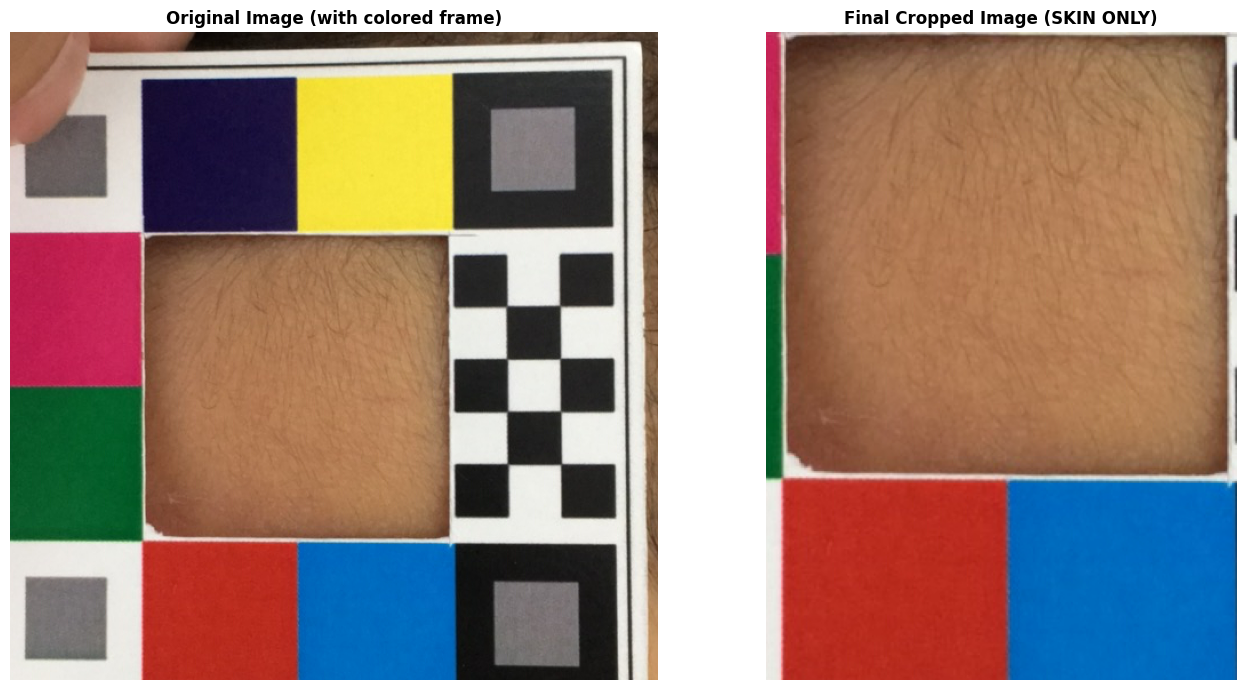


📊 Crop Summary:
  Original size: 567×567
  Cropped size:  391×284

✅ Saved to: /Users/shubhbhateja/College/minor_project/skin_cropped/cropped_0001-1.jpg


In [26]:
# ── Load a specific single image for pixel assessment ──
specific_image_name = '0001-1.jpg'  # Change this to any image you want
img = images[specific_image_name]

print(f"Loaded image: {specific_image_name}")
print(f"Image shape: {img.shape}")
print(f"Image dtype: {img.dtype}")
print(f"Pixel value range: Min={img.min()}, Max={img.max()}\n")

# Display the image with a larger figure for better inspection
fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(img)
ax.set_title(f'Image: {specific_image_name}\n(Hover over pixels to see values)', fontsize=14, fontweight='bold')
plt.colorbar(im, ax=ax)

# Enable pixel value inspection on mouse movement (Mac compatible)
def on_move(event):
    if event.inaxes != ax:
        return
    x, y = int(event.xdata), int(event.ydata)
    if 0 <= x < img.shape[1] and 0 <= y < img.shape[0]:
        pixel = img[y, x]
        ax.set_title(f'Image: {specific_image_name} | Pixel [{y}, {x}] = RGB({pixel[0]}, {pixel[1]}, {pixel[2]})', fontsize=12)
        fig.canvas.draw_idle()

fig.canvas.mpl_connect('motion_notify_event', on_move)
plt.tight_layout()
plt.show()

# ── Manual pixel inspection ──
print("\n" + "="*60)
print("MANUAL PIXEL INSPECTION")
print("="*60)

# Check specific pixel coordinates
test_pixels = [(0, 0), (100, 100), (img.shape[0]//2, img.shape[1]//2)]

for y, x in test_pixels:
    if 0 <= y < img.shape[0] and 0 <= x < img.shape[1]:
        pixel = img[y, x]
        print(f"Pixel at [{y}, {x}]: RGB({pixel[0]}, {pixel[1]}, {pixel[2]})")

# ── Get statistics about pixel values ──
print("\n" + "="*60)
print("PIXEL STATISTICS")
print("="*60)
for i, color in enumerate(['Red', 'Green', 'Blue']):
    channel = img[:, :, i]
    print(f"\n{color} Channel:")
    print(f"  Min: {channel.min()}, Max: {channel.max()}, Mean: {channel.mean():.2f}, Std: {channel.std():.2f}")
#load specific image
img = images['0001-1.jpg']
img_path = os.path.join(IMAGE_DIR, '0002-1.jpg')
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# ────────────────────────────────────────────────────────────────
# EXTRACT CENTRAL SKIN REGION ONLY
# ────────────────────────────────────────────────────────────────
# This extracts ONLY the brown/tan skin area, removing all colored frames

crop_image_name = '0001-1.jpg'  # ← CHANGE THIS TO ANY IMAGE YOU WANT
original_img = images[crop_image_name].copy()

print(f"Original image shape: {original_img.shape}")

# ── Method: Detect the largest brown/skin-colored region ──
# Convert to HSV for skin tone detection
hsv = cv2.cvtColor(original_img, cv2.COLOR_RGB2HSV)

# Define range for skin/brown tones (approximate)
# Skin tone typically: H=0-20, S=10-60, V=60-255
lower_skin = np.array([0, 10, 60])
upper_skin = np.array([25, 200, 255])
skin_mask = cv2.inRange(hsv, lower_skin, upper_skin)

# Apply morphological operations to clean up the mask
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
skin_mask = cv2.morphologyEx(skin_mask, cv2.MORPH_CLOSE, kernel)
skin_mask = cv2.morphologyEx(skin_mask, cv2.MORPH_OPEN, kernel)

# Find contours
contours, _ = cv2.findContours(skin_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

if contours:
    # Get the largest contour (the skin region)
    largest_contour = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(largest_contour)
    
    # Extract bounding box (this removes all colored frames)
    cropped_img = original_img[y:y+h, x:x+w]
    print(f"✅ Cropped to skin region: {cropped_img.shape}")
else:
    print("⚠️  Skin detection failed, showing original")
    cropped_img = original_img

# ── Display original vs final cropped skin ──
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(original_img)
axes[0].set_title('Original Image (with colored frame)', fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cropped_img)
axes[1].set_title('Final Cropped Image (SKIN ONLY)', fontsize=12, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"\n📊 Crop Summary:")
print(f"  Original size: {original_img.shape[0]}×{original_img.shape[1]}")
print(f"  Cropped size:  {cropped_img.shape[0]}×{cropped_img.shape[1]}")

# ── Save cropped image ──
output_dir = '/Users/shubhbhateja/College/minor_project/skin_cropped'
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, f"cropped_{crop_image_name}")
cropped_bgr = cv2.cvtColor(cropped_img, cv2.COLOR_RGB2BGR)
cv2.imwrite(output_path, cropped_bgr)
print(f"\n✅ Saved to: {output_path}")

Original image shape: (567, 567, 3)
✅ Cropped to skin region (after shrinking): (361, 254, 3)


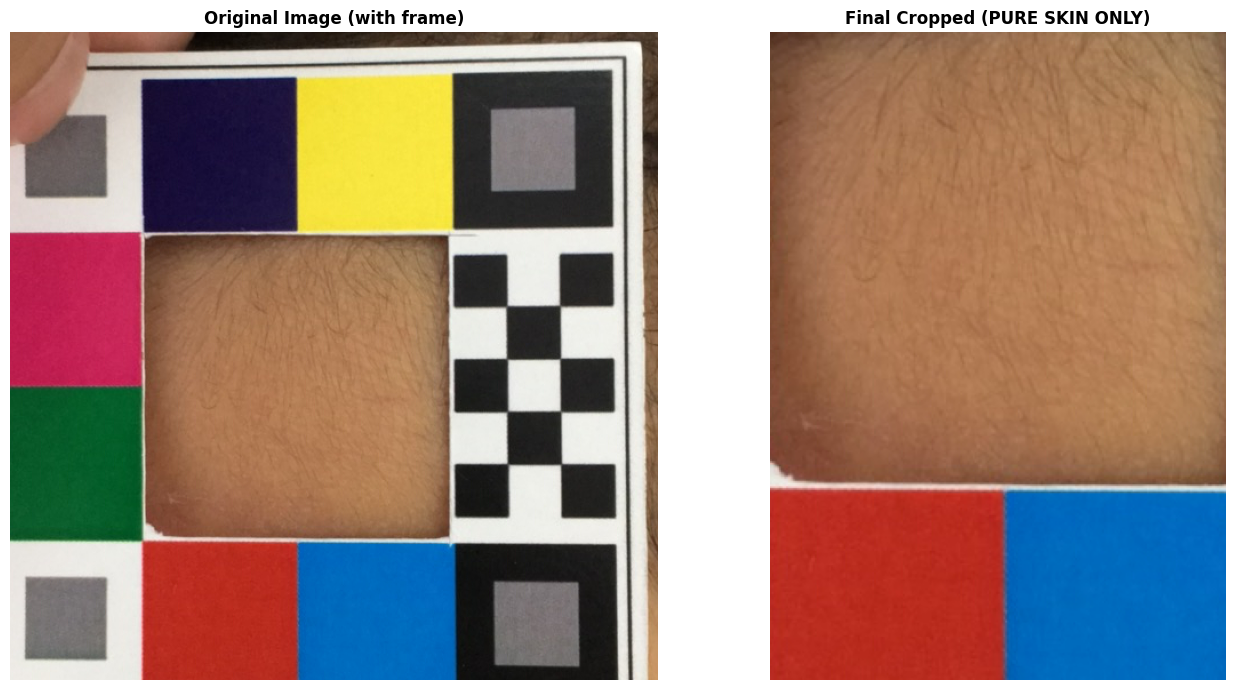


📊 Crop Summary:
  Original:  567×567
  Cropped:   361×254
✅ Saved to: /Users/shubhbhateja/College/minor_project/skin_cropped/cropped_0001-1.jpg

💡 If you still see colored edges:
  Increase the shrink values at the top of this cell
  shrink_top, shrink_bottom, shrink_left, shrink_right


In [29]:
# ────────────────────────────────────────────────────────────────
# PRECISE SKIN REGION EXTRACTION - REMOVE ALL COLORED BORDERS
# ────────────────────────────────────────────────────────────────

crop_image_name = '0001-1.jpg'  # ← CHANGE THIS TO ANY IMAGE YOU WANT
original_img = images[crop_image_name].copy()

print(f"Original image shape: {original_img.shape}")

# ── Detect skin region and shrink inward to remove borders ──
hsv = cv2.cvtColor(original_img, cv2.COLOR_RGB2HSV)

# Skin/brown tone detection
lower_skin = np.array([0, 10, 60])
upper_skin = np.array([25, 200, 255])
skin_mask = cv2.inRange(hsv, lower_skin, upper_skin)

# Clean up
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
skin_mask = cv2.morphologyEx(skin_mask, cv2.MORPH_CLOSE, kernel)
skin_mask = cv2.morphologyEx(skin_mask, cv2.MORPH_OPEN, kernel)

# Find contours
contours, _ = cv2.findContours(skin_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

if contours:
    largest_contour = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(largest_contour)
    
    # ── SHRINK THE BOUNDING BOX INWARD TO REMOVE COLORED EDGES ──
    # Adjust these values if needed (pixels to shrink from each side)
    shrink_top = 15
    shrink_bottom = 15
    shrink_left = 15
    shrink_right = 15
    
    x1 = x + shrink_left
    y1 = y + shrink_top
    x2 = x + w - shrink_right
    y2 = y + h - shrink_bottom
    
    # Ensure coordinates are valid
    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(original_img.shape[1], x2)
    y2 = min(original_img.shape[0], y2)
    
    # Extract the refined skin region
    cropped_img = original_img[y1:y2, x1:x2]
    print(f"✅ Cropped to skin region (after shrinking): {cropped_img.shape}")
else:
    print("⚠️  Skin detection failed")
    cropped_img = original_img

# ── Display comparison ──
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(original_img)
axes[0].set_title('Original Image (with frame)', fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cropped_img)
axes[1].set_title('Final Cropped (PURE SKIN ONLY)', fontsize=12, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"\n📊 Crop Summary:")
print(f"  Original:  {original_img.shape[0]}×{original_img.shape[1]}")
print(f"  Cropped:   {cropped_img.shape[0]}×{cropped_img.shape[1]}")

# ── Save ──
output_dir = '/Users/shubhbhateja/College/minor_project/skin_cropped'
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, f"cropped_{crop_image_name}")
cropped_bgr = cv2.cvtColor(cropped_img, cv2.COLOR_RGB2BGR)
cv2.imwrite(output_path, cropped_bgr)
print(f"✅ Saved to: {output_path}")

# ── ADJUSTMENT GUIDE ──
print("\n" + "="*70)
print("💡 If you still see colored edges:")
print("  Increase the shrink values at the top of this cell")
print("  shrink_top, shrink_bottom, shrink_left, shrink_right")
print("="*70)


Original image shape: (567, 567, 3)
✅ Cropped to skin region (after shrinking): (256, 254, 3)


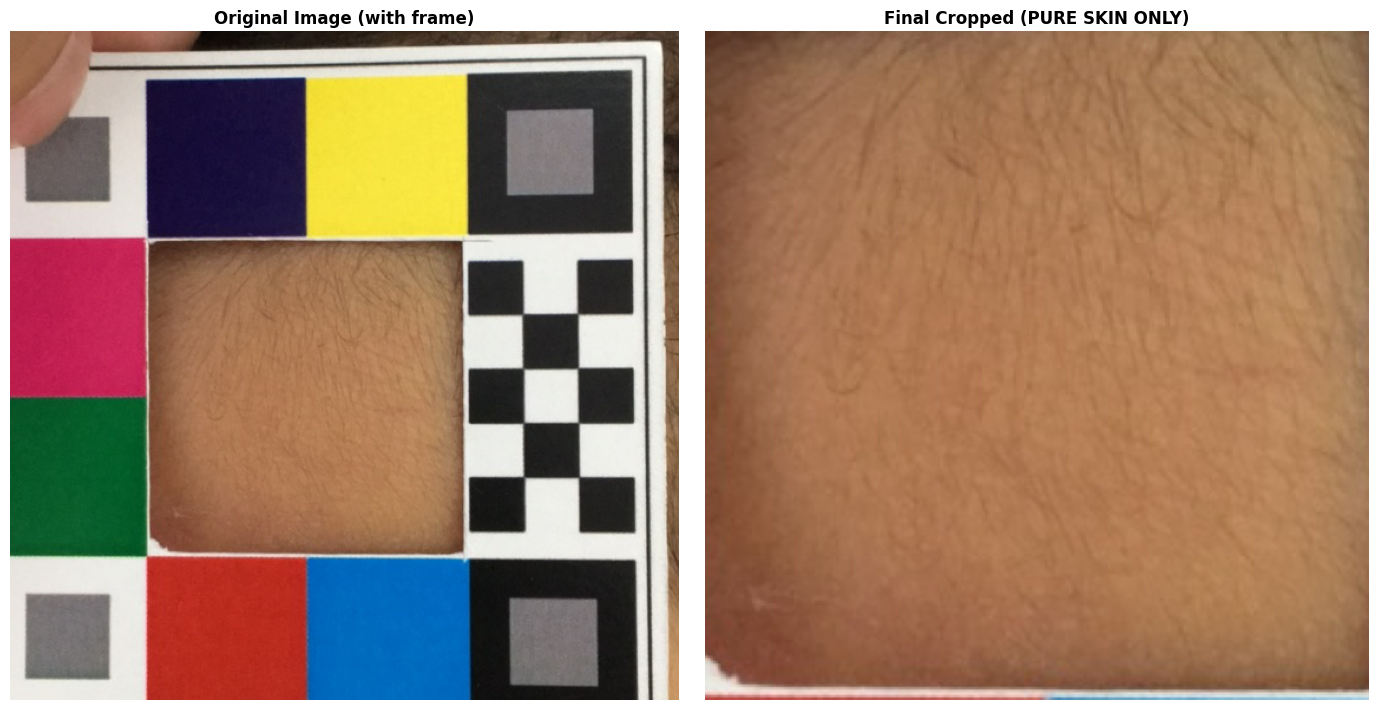


📊 Crop Summary:
  Original:  567×567
  Cropped:   256×254
✅ Saved to: /Users/shubhbhateja/College/minor_project/skin_cropped/cropped_0001-1.jpg

💡 If you still see colored edges:
  Increase the shrink values at the top of this cell
  shrink_top, shrink_bottom, shrink_left, shrink_right


In [ ]:
# ────────────────────────────────────────────────────────────────
# PRECISE SKIN REGION EXTRACTION - REMOVE ALL COLORED BORDERS
# ────────────────────────────────────────────────────────────────

crop_image_name = '0001-1.jpg'  # ← CHANGE THIS TO ANY IMAGE YOU WANT
original_img = images[crop_image_name].copy()

print(f"Original image shape: {original_img.shape}")

# ── Detect skin region and shrink inward to remove borders ──
hsv = cv2.cvtColor(original_img, cv2.COLOR_RGB2HSV)

# Skin/brown tone detection
lower_skin = np.array([0, 10, 60])
upper_skin = np.array([25, 200, 255])
skin_mask = cv2.inRange(hsv, lower_skin, upper_skin)

# Clean up
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
skin_mask = cv2.morphologyEx(skin_mask, cv2.MORPH_CLOSE, kernel)
skin_mask = cv2.morphologyEx(skin_mask, cv2.MORPH_OPEN, kernel)

# Find contours
contours, _ = cv2.findContours(skin_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

if contours:
    largest_contour = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(largest_contour)
    
    # ── SHRINK THE BOUNDING BOX INWARD TO REMOVE COLORED EDGES ──
    # Adjust these values if needed (pixels to shrink from each side)
    shrink_top = 15
    shrink_bottom = 120
    shrink_left = 15
    shrink_right = 15
    
    x1 = x + shrink_left
    y1 = y + shrink_top
    x2 = x + w - shrink_right
    y2 = y + h - shrink_bottom
    
    # Ensure coordinates are valid
    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(original_img.shape[1], x2)
    y2 = min(original_img.shape[0], y2)
    
    # Extract the refined skin region
    cropped_img = original_img[y1:y2, x1:x2]
    print(f"✅ Cropped to skin region (after shrinking): {cropped_img.shape}")
else:
    print("⚠️  Skin detection failed")
    cropped_img = original_img

# ── Display comparison ──
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(original_img)
axes[0].set_title('Original Image (with frame)', fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cropped_img)
axes[1].set_title('Final Cropped (PURE SKIN ONLY)', fontsize=12, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"\n📊 Crop Summary:")
print(f"  Original:  {original_img.shape[0]}×{original_img.shape[1]}")
print(f"  Cropped:   {cropped_img.shape[0]}×{cropped_img.shape[1]}")

# ── Save ──
output_dir = '/Users/shubhbhateja/College/minor_project/skin_cropped'
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(output_dir, f"cropped_{crop_image_name}")
cropped_bgr = cv2.cvtColor(cropped_img, cv2.COLOR_RGB2BGR)
cv2.imwrite(output_path, cropped_bgr)
print(f"✅ Saved to: {output_path}")

# ── ADJUSTMENT GUIDE ──
print("\n" + "="*70)
print("💡 If you still see colored edges:")
print("  Increase the shrink values at the top of this cell")
print("  shrink_top, shrink_bottom, shrink_left, shrink_right")
print("="*70)


In [3]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ── CONFIGURATION ──
IMAGE_DIR = '/Users/shubhbhateja/College/minor_project/images'
OUTPUT_DIR = '/Users/shubhbhateja/College/minor_project/cropped_skin_patches'
os.makedirs(OUTPUT_DIR, exist_ok=True)

image_files = sorted([f for f in os.listdir(IMAGE_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

def adaptive_crop_skin(image_rgb):
    """
    Advanced skin cropper that avoids borders, background patches, 
    and non-skin elements by using morphological shrinking.
    """
    h, w = image_rgb.shape[:2]
    
    # 1. Convert to YCrCb for skin detection
    img_ycrcb = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2YCrCb)
    
    # 2. Skin Color Range (Tighter bounds to avoid shadows/edges)
    lower_skin = np.array([0, 135, 85], dtype=np.uint8)
    upper_skin = np.array([255, 175, 135], dtype=np.uint8)
    mask = cv2.inRange(img_ycrcb, lower_skin, upper_skin)
    
    # 3. CRITICAL: Remove the bottom 20% immediately (kills the info patches)
    mask[int(h*0.80):h, :] = 0
    # Also remove thin 5% strip from all edges to avoid dark vignettes
    mask[0:int(h*0.05), :] = 0
    mask[:, 0:int(w*0.05)] = 0
    mask[:, int(w*0.95):w] = 0

    # 4. Clean up the mask and SHRINK it (Erosion)
    # This moves the boundary AWAY from the edges of the arm/background
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel) # Remove noise
    mask = cv2.erode(mask, kernel, iterations=3)         # Pull away from borders
    
    # 5. Find the main skin "island"
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours:
        # Fallback: If skin detection fails, take a safe center crop
        return image_rgb[int(h*0.2):int(h*0.7), int(w*0.2):int(w*0.8)]
        
    largest_cnt = max(contours, key=cv2.contourArea)
    x, y, w_box, h_box = cv2.boundingRect(largest_cnt)
    
    # 6. Apply an INNER INSET
    # We take the detected box and shrink it by 10% more to be safe
    inset_x = int(w_box * 0.1)
    inset_y = int(h_box * 0.1)
    
    y1, y2 = y + inset_y, y + h_box - inset_y
    x1, x2 = x + inset_x, x + w_box - inset_x
    
    # Final Crop
    cropped = image_rgb[y1:y2, x1:x2]
    
    # Safety check: if the crop is empty or tiny, return a standard center
    if cropped.size == 0 or cropped.shape[0] < 50:
        return image_rgb[int(h*0.2):int(h*0.7), int(w*0.2):int(w*0.8)]
        
    return cropped

# ── PROCESS ALL ──
print(f"Processing {len(image_files)} images...")
for fname in image_files:
    img_path = os.path.join(IMAGE_DIR, fname)
    img = cv2.imread(img_path)
    if img is not None:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        try:
            cropped_skin = adaptive_crop_skin(img_rgb)
            final_bgr = cv2.cvtColor(cropped_skin, cv2.COLOR_RGB2BGR)
            cv2.imwrite(os.path.join(OUTPUT_DIR, fname), final_bgr)
        except Exception as e:
            print(f"Error on {fname}: {e}")

print("Done! Check the folder.")

Processing 2235 images...
Done! Check the folder.
